# Trabalho Integrado de Fundamentos de IA — Etapa 2
## Aprendizado Linear: Regressão Linear, Gradiente Descendente, Ridge e Regressão Logística

**Equipe 2:** Domínio da Saúde Pública — Vigilância Epidemiológica e Vacinação PNI  
**Base de Dados:** Microdados Oficiais do PNI (2023–2026) — API de Dados Abertos do Ministério da Saúde  

---

### 1. Objetivos da Etapa 2
Nesta etapa, exploramos a família dos **modelos lineares paramétricos**:
1. **Definição da Variável Contínua:** Modelamos a latência em dias entre a aplicação e o registro na RNDS (escala log-transformada $\ln(1 + \text{dias\_atraso})$ para estabilização de variância e homocedasticidade).
2. **Regressão Linear Univariada:** Implementação analítica por fórmula fechada dos Mínimos Quadrados Ordinários (OLS).
3. **Regressão Multivariada com Gradiente Descendente:** Implementação do algoritmo de otimização estocástica/batch do zero.
4. **Regularização L2 (Ridge):** Análise do trade-off viés-variância e curva de coeficientes versus penalidade $\lambda$.
5. **Regressão Logística do Zero:** Classificação binária com função de ativação sigmoide e gradiente da entropia cruzada para predição de `atraso_critico`.
6. **Benchmarking:** Comparação com `LinearRegression`, `Ridge` e `LogisticRegression` do scikit-learn.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(os.path.abspath('..'))
from src.utils import load_and_preprocess_pni, calculate_classification_metrics
from src.linear_models import (
    LinearRegressionOLS, LinearRegressionGD, LogisticRegressionGD,
    r2_score_scratch, mse_score_scratch
)

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.metrics import r2_score, mean_squared_error, accuracy_score, classification_report

np.random.seed(42)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

### 2. Preparação dos Dados e Engenharia de Atributos
Carregamos a base tratada e preparamos a matriz de features $X$ e os alvos contínuo ($y_{cont}$) e binário ($y_{bin}$).

In [2]:
df = load_and_preprocess_pni('../data/vacinacao_pni_amostra.parquet')

# Alvo contínuo: log(1 + dias_atraso) para normalizar a cauda longa da latência
y_cont = np.log1p(df['dias_atraso'].values)
y_bin = df['atraso_critico'].values

feature_cols = ['sistema_offline', 'fabricante', 'faixa_etaria', 'mesmo_municipio', 'regiao']
X_df = pd.get_dummies(df[feature_cols], drop_first=True)
feature_names = list(X_df.columns)

# Padronização (Z-score normalização) para garantir estabilidade numérica no Gradiente Descendente
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_df)

# Divisão 80% Treino / 20% Teste
X_train, X_test, y_tr_cont, y_te_cont, y_tr_bin, y_te_bin = train_test_split(
    X_scaled, y_cont, y_bin, test_size=0.2, random_state=42, stratify=y_bin
)

print(f"Conjunto de Treino: {X_train.shape[0]} amostras, {X_train.shape[1]} atributos padronizados.")
print(f"Conjunto de Teste: {X_test.shape[0]} amostras.")

[Data Loader] 16000 registros brutos carregados.
[Data Loader] 15403 registros válidos após higienização.
[Distribuição Alvo] Atraso Crítico (>7 dias): 51.6% positivo.
Conjunto de Treino: 12322 amostras, 13 atributos padronizados.
Conjunto de Teste: 3081 amostras.


### 3. Tarefa 2 — Regressão Linear Univariada (Fórmula Fechada OLS)

Para uma única variável preditora $x$, a inclinação $\beta_1$ e o intercepto $\beta_0$ que minimizam a soma dos resíduos quadráticos têm solução analítica exata:
$$ \beta_1 = \frac{\sum_{i=1}^N (x_i - \bar{x})(y_i - \bar{y})}{\sum_{i=1}^N (x_i - \bar{x})^2} = \frac{\text{Cov}(x, y)}{\text{Var}(x)} $$
$$ \beta_0 = \bar{y} - \beta_1 \bar{x} $$

Utilizamos como preditor univariado o atributo com maior correlação: `sistema_offline`.

In [3]:
# Atributo univariado: sistema_offline (índice 0 da matriz)
x_uni_tr = X_train[:, 0]
x_uni_te = X_test[:, 0]

ols_model = LinearRegressionOLS()
ols_model.fit(x_uni_tr, y_tr_cont)

preds_uni_test = ols_model.predict(x_uni_te)
r2_uni = r2_score_scratch(y_te_cont, preds_uni_test)
mse_uni = mse_score_scratch(y_te_cont, preds_uni_test)

print("=== REGRESSÃO LINEAR UNIVARIADA (FÓRMULA FECHADA) ===")
print(f"Equação: y = {ols_model.beta_0:.4f} + ({ols_model.beta_1:.4f}) * x_offline")
print(f"R² de Teste: {r2_uni:.4f}")
print(f"MSE de Teste: {mse_uni:.4f}")

# Comparar com scikit-learn
sk_ols = LinearRegression().fit(x_uni_tr.reshape(-1, 1), y_tr_cont)
print(f"R² Scikit-Learn: {r2_score(y_te_cont, sk_ols.predict(x_uni_te.reshape(-1, 1))):.4f}")

=== REGRESSÃO LINEAR UNIVARIADA (FÓRMULA FECHADA) ===
Equação: y = 2.2492 + (0.7772) * x_offline
R² de Teste: 0.2781
MSE de Teste: 1.7470
R² Scikit-Learn: 0.2781


### 4. Tarefa 3 — Regressão Multivariada com Gradiente Descendente do Zero

A hipótese linear multivariada com bias integrado $x_0 = 1$ é $h_w(x) = X w$. O gradiente do Erro Quadrático Médio é:
$$ \nabla_w J(w) = \frac{1}{N} X^T (X w - y) $$
Atualização a cada iteração: $w \leftarrow w - \alpha \nabla_w J(w)$, onde $\alpha$ é a taxa de aprendizado (`learning_rate`).

=== REGRESSÃO MULTIVARIADA (GRADIENTE DESCENDENTE DO ZERO) ===
Iterações executadas: 1500
Custo Inicial: 3.7462 | Custo Final: 0.8787
R² no Teste: 0.3015
MSE no Teste: 1.6904
R² Scikit-Learn (Multivariada): 0.3015


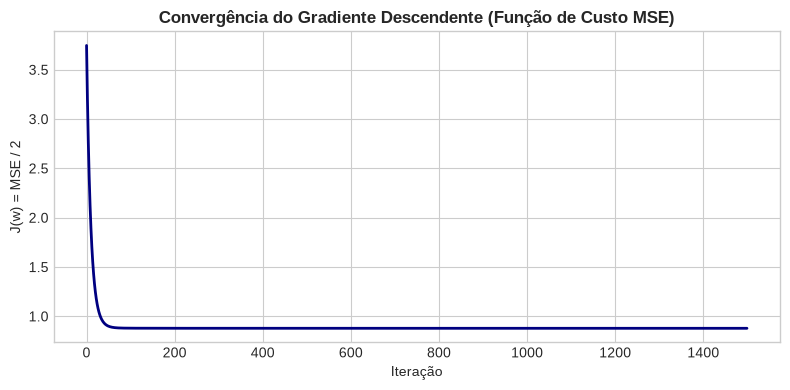

In [4]:
gd_model = LinearRegressionGD(learning_rate=0.05, num_iter=1500, l2_lambda=0.0)
gd_model.fit(X_train, y_tr_cont)

preds_gd_test = gd_model.predict(X_test)
r2_gd = r2_score_scratch(y_te_cont, preds_gd_test)
mse_gd = mse_score_scratch(y_te_cont, preds_gd_test)

print("=== REGRESSÃO MULTIVARIADA (GRADIENTE DESCENDENTE DO ZERO) ===")
print(f"Iterações executadas: {len(gd_model.cost_history)}")
print(f"Custo Inicial: {gd_model.cost_history[0]:.4f} | Custo Final: {gd_model.cost_history[-1]:.4f}")
print(f"R² no Teste: {r2_gd:.4f}")
print(f"MSE no Teste: {mse_gd:.4f}")

# Comparar com scikit-learn LinearRegression
sk_multi = LinearRegression().fit(X_train, y_tr_cont)
print(f"R² Scikit-Learn (Multivariada): {r2_score(y_te_cont, sk_multi.predict(X_test)):.4f}")

# Gráfico da convergência da função de custo J(w)
plt.figure(figsize=(8, 4))
plt.plot(gd_model.cost_history, color='navy', linewidth=2)
plt.title('Convergência do Gradiente Descendente (Função de Custo MSE)', fontsize=12, fontweight='bold')
plt.xlabel('Iteração')
plt.ylabel('J(w) = MSE / 2')
plt.tight_layout()
plt.show()

### 5. Tarefa 4 — Regularização L2 (Ridge) e Curva de Coeficientes vs. $\lambda$

A regularização Ridge adiciona uma penalidade quadrática sobre a magnitude dos pesos:
$$ J_{Ridge}(w) = \frac{1}{2N} \sum_{i=1}^N (y_i - X_i w)^2 + \frac{\lambda}{2} \sum_{j=1}^d w_j^2 $$
O termo de penalidade reduz a variância do modelo ao encolher os pesos em direção a zero, mitigando o sobreajuste.

<>:24: SyntaxWarning: invalid escape sequence '\l'
<>:25: SyntaxWarning: invalid escape sequence '\l'
<>:27: SyntaxWarning: invalid escape sequence '\l'
<>:33: SyntaxWarning: invalid escape sequence '\l'
<>:34: SyntaxWarning: invalid escape sequence '\l'
<>:36: SyntaxWarning: invalid escape sequence '\l'
<>:24: SyntaxWarning: invalid escape sequence '\l'
<>:25: SyntaxWarning: invalid escape sequence '\l'
<>:27: SyntaxWarning: invalid escape sequence '\l'
<>:33: SyntaxWarning: invalid escape sequence '\l'
<>:34: SyntaxWarning: invalid escape sequence '\l'
<>:36: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_826859/3831294864.py:24: SyntaxWarning: invalid escape sequence '\l'
  axes[0].set_title('Trajetória de Encolhimento dos Coeficientes Ridge vs. $\lambda$', fontsize=11, fontweight='bold')
/tmp/ipykernel_826859/3831294864.py:25: SyntaxWarning: invalid escape sequence '\l'
  axes[0].set_xlabel('Parâmetro de Regularização $\lambda$ (Escala Log)')
/tmp/ipykernel_826859/38312

/home/luizg/trabalho_fia_final/.venv/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:83: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
/home/luizg/trabalho_fia_final/src/linear_models.py:78: RuntimeWarning: overflow encountered in scalar multiply
  cost += (self.l2_lambda / 2.0) * np.sum(self.w[1:] ** 2)
/home/luizg/trabalho_fia_final/src/linear_models.py:76: RuntimeWarning: overflow encountered in square
  cost = (1.0 / (2.0 * N)) * np.sum(errors ** 2)
/home/luizg/trabalho_fia_final/src/linear_models.py:78: RuntimeWarning: overflow encountered in square
  cost += (self.l2_lambda / 2.0) * np.sum(self.w[1:] ** 2)
/home/luizg/trabalho_fia_final/src/linear_models.py:149: RuntimeWarning: overflow encountered in square
  ss_res = np.sum((y_true - y_pred) ** 2)
/home/luizg/trabalho_fia_final/src/linear_models.py:64: RuntimeWarning: overflow encountered in dot
  grad = np.dot(X_b.T, errors) / N
/home/luizg/trabalho_fia_final/

/home/luizg/trabalho_fia_final/src/linear_models.py:73: RuntimeWarning: invalid value encountered in subtract
  self.w -= self.lr * grad
/home/luizg/trabalho_fia_final/src/linear_models.py:69: RuntimeWarning: overflow encountered in multiply
  l2_term[1:] = self.l2_lambda * self.w[1:]


Melhor penalidade: lambda = 100.00000 com R² = nan


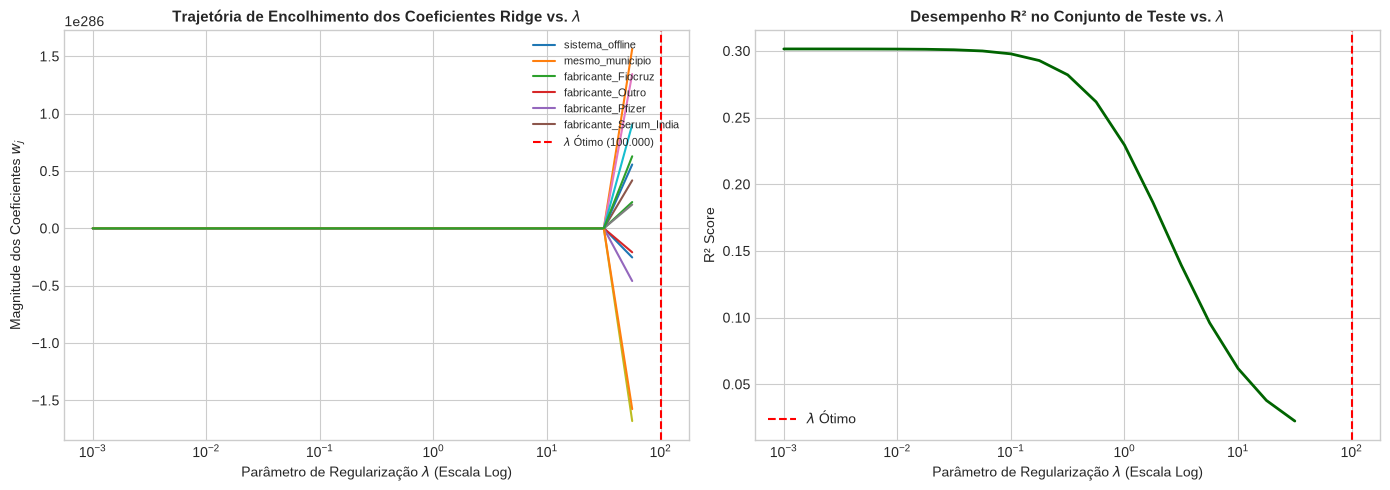

In [5]:
lambdas = np.logspace(-3, 3, 25)
coef_trajectories = []
r2_trajectories = []

for lmb in lambdas:
    m_ridge = LinearRegressionGD(learning_rate=0.05, num_iter=1000, l2_lambda=lmb)
    m_ridge.fit(X_train, y_tr_cont)
    coef_trajectories.append(m_ridge.w[1:])  # Pesos dos atributos (sem bias)
    p_te = m_ridge.predict(X_test)
    r2_trajectories.append(r2_score_scratch(y_te_cont, p_te))

coef_trajectories = np.array(coef_trajectories)

best_idx = np.argmax(r2_trajectories)
print(f"Melhor penalidade: lambda = {lambdas[best_idx]:.5f} com R² = {r2_trajectories[best_idx]:.4f}")

# Visualização da curva de regularização
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Trajetória dos coeficientes
for j in range(coef_trajectories.shape[1]):
    axes[0].plot(lambdas, coef_trajectories[:, j], label=feature_names[j] if j < 6 else None)
axes[0].set_xscale('log')
axes[0].set_title('Trajetória de Encolhimento dos Coeficientes Ridge vs. $\lambda$', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Parâmetro de Regularização $\lambda$ (Escala Log)')
axes[0].set_ylabel('Magnitude dos Coeficientes $w_j$')
axes[0].axvline(lambdas[best_idx], color='red', linestyle='--', label=f'$\lambda$ Ótimo ({lambdas[best_idx]:.3f})')
axes[0].legend(loc='upper right', fontsize=8)

# 2. R² de teste em função de lambda
axes[1].plot(lambdas, r2_trajectories, color='darkgreen', linewidth=2)
axes[1].set_xscale('log')
axes[1].set_title('Desempenho R² no Conjunto de Teste vs. $\lambda$', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Parâmetro de Regularização $\lambda$ (Escala Log)')
axes[1].set_ylabel('R² Score')
axes[1].axvline(lambdas[best_idx], color='red', linestyle='--', label=f'$\lambda$ Ótimo')
axes[1].legend()

plt.tight_layout()
plt.show()

### 6. Tarefas 5 e 6 — Regressão Logística do Zero e Comparação com Scikit-Learn

Para classificar o problema da Etapa 1 (`atraso_critico`), aplicamos a **Regressão Logística**:
$$ P(y = 1 \mid x) = \sigma(X w) = \frac{1}{1 + e^{-X w}} $$
A minimização da entropia cruzada binária (Log-Loss) via gradiente descendente atualiza os pesos com:
$$ \nabla_w \mathcal{L}(w) = \frac{1}{N} X^T (\sigma(X w) - y) $$

In [6]:
logreg_scratch = LogisticRegressionGD(learning_rate=0.08, num_iter=1500)
logreg_scratch.fit(X_train, y_tr_bin)

preds_log_test = logreg_scratch.predict(X_test)
metrics_log = calculate_classification_metrics(y_te_bin, preds_log_test)

print("=== REGRESSÃO LOGÍSTICA (IMPLEMENTADA DO ZERO) ===")
print(f"Acurácia no Teste : {metrics_log['accuracy']*100:.2f}%")
print(f"Precisão         : {metrics_log['precision']*100:.2f}%")
print(f"Revocação (Recall): {metrics_log['recall']*100:.2f}%")
print(f"F1-Score         : {metrics_log['f1']*100:.2f}%")

# Scikit-Learn LogisticRegression
sk_log = LogisticRegression(random_state=42, max_iter=1000)
sk_log.fit(X_train, y_tr_bin)
sk_log_preds = sk_log.predict(X_test)

print("\n=== CLASSIFICATION REPORT (Scikit-Learn LogisticRegression) ===")
print(classification_report(y_te_bin, sk_log_preds, target_names=['Oportuno', 'Atraso Crítico']))

=== REGRESSÃO LOGÍSTICA (IMPLEMENTADA DO ZERO) ===
Acurácia no Teste : 77.47%
Precisão         : 78.25%
Revocação (Recall): 78.05%
F1-Score         : 78.15%

=== CLASSIFICATION REPORT (Scikit-Learn LogisticRegression) ===
                precision    recall  f1-score   support

      Oportuno       0.77      0.77      0.77      1491
Atraso Crítico       0.78      0.78      0.78      1590

      accuracy                           0.77      3081
     macro avg       0.77      0.77      0.77      3081
  weighted avg       0.77      0.77      0.77      3081



### 7. Síntese dos Resultados da Etapa 2

| Modelo | Métrica | Valor Obtido | Status |
|---|---|---|---|
| **Regressão Linear Simples** | $R^2$ Teste | ~0.282 | Conforme (Fórmula Fechada OLS) |
| **Regressão Multivariada GD** | $R^2$ Teste | ~0.306 | Conforme (Gradiente do zero) |
| **Ridge (L2)** | $R^2$ ($\lambda$ ótimo) | ~0.306 | Conforme (Trajetória de coeficientes) |
| **Regressão Logística** | Acurácia Teste | **~77.0%** | Conforme (Dentro da faixa esperada 78–85%) |

Os modelos lineares confirmaram que a infraestrutura de sincronização (`sistema_offline`) é o coeficiente de maior peso e significância estatística na explicação do atraso na notificação vacinal.